# Figure 7 — Tourism ticket receipts and modeled facility-capacity equivalent

This notebook generates **Figure 7 for Section 4.5.2** from explicit scenario equations. It does not use image generation. Outputs are *conditional model scenarios*, **not** independently validated projections of fiscal revenue or site infrastructure.

## Source observations and tariffs

- Observed 2024 Gunung Bromo admissions: 465,770 domestic + 19,926 international = 485,696 total (ANTARA, 12 June 2025): https://www.antaranews.com/berita/4895561/tnbts-memperketat-pengawasan-di-bromo-cegah-masuknya-wisatawan-ilegal
- Official entrance tariff effective 30 October 2024: IDR 54,000 domestic weekday; IDR 79,000 domestic holiday; IDR 255,000 international. These face prices include insurance (BB TNBTS): https://bromotenggersemeru.org/article/pengumuman-penyesuaian-tarif-tnbts-sesuai-pp-36-tahun-2024/
- **Annual-average visits** are annual admissions divided by calendar days; they do not measure concurrent visitor stocks.

## Scenario assumptions

- Visitor demand base: 2024 admissions / 366 calendar days.
- Business-as-usual visitation growth: 4.68% per year (2025–2045).
- Intervention: 2025 follows BAU; starting 2026, 3.5% annual demand growth, with a one-off assumed linear price response. Domestic tariff *multiplier* 1.08, international 1.25; elasticity −0.504. The growth and elasticity parameters are **assumed, not destination-specific estimates**.
- Blended domestic tariff weights **5 weekdays / 2 holidays**, a simplification without observed transaction-level day mix. Calculated ticket values are **hypothetical gross nominal ticket receipts**, *not* observed PNBP, net fiscal revenue, or officially approved allocations.
- Facility model is an **assumption-based accounting stock** adapted from the repository's `Tourism_Facilities_Availability_Subsystem.ipynb`: initial scenario budget IDR 3,976,500,000, initial capacity-equivalent 2,752 visitor-handling units/day, assumed 85% of ticket face-value as funding proxy, 90% annual budget absorption, 18% BAU capital allocation and 30% intervention allocation from 2026, assumed investment cost IDR 20 million per capacity-equivalent unit, annual depreciation 14.3%, overuse factor 0.0008, and imposed capacity ceiling of 3,500. None are verified fiscal authorizations or measured facility capacity. The initial 2,752 is **numerically aligned** with an operational quota; this does not establish that a visitor quota measures physical facilities.
- The facility model runs daily on annual-mean admission-demand proxies. Thus it does not model day-of-week or seasonal crowding. The annual summary uses *end-of-year* capacity-equivalent state, not an annual average or external capacity observation.

Outputs: `ATR_Fig7_Revenue_Facilities_Executed_300dpi.png`, `ATR_Fig7_Scenario_Output_2025_2045.csv`. All numerical claims should reference these definitions and the exact implementation version; this is not a reproduction of the older embedded notebook figure or a fully coupled seven-subsystem model.


In [1]:
from pathlib import Path
from calendar import isleap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

OUT = Path.cwd()  # In Google Colab, outputs are written under /content
OBSERVED_2024_DOM = 465_770
OBSERVED_2024_FOR = 19_926
OBSERVED_2024_DAYS = 366
START_YEAR, END_YEAR = 2025, 2045
BAU_GROWTH = 0.0468
INT_GROWTH = 0.035
ELASTICITY_ASSUMPTION = -0.504
DOM_PRICE_MULTIPLIER = 1.08
FOR_PRICE_MULTIPLIER = 1.25
DOM_WEEKDAY_TARIFF = 54_000
DOM_HOLIDAY_TARIFF = 79_000
FOREIGN_TARIFF = 255_000
ASSUMED_WEEKDAY_SHARE = 5/7
DOM_TARIFF_BLEND = (ASSUMED_WEEKDAY_SHARE * DOM_WEEKDAY_TARIFF
                    + (1-ASSUMED_WEEKDAY_SHARE) * DOM_HOLIDAY_TARIFF)

INITIAL_SCENARIO_BUDGET_IDR = 3_976_500_000
INITIAL_FACILITY_EQUIV = 2_752
ASSUMED_BUDGET_FRACTION = 0.85  # hypothetical, NOT actual funds available from PNBP
ANNUAL_ABSORPTION = 0.90
BAU_CAPEX_FRACTION = 0.18
INT_CAPEX_FRACTION = 0.30
COST_PER_EQUIV_UNIT_IDR = 20_000_000
ANNUAL_DEPRECIATION = 0.143
EXCESS_DEMAND_DAMAGE_FACTOR = 0.0008
FACILITY_EQUIV_CEILING = 3_500

assert OBSERVED_2024_DOM + OBSERVED_2024_FOR == 485_696
assert 0 <= ASSUMED_WEEKDAY_SHARE <= 1
print(f'2024 observed admission average: {485696/366:.2f}/day')
print(f'Assumed domestic ticket blend: IDR {DOM_TARIFF_BLEND:,.2f}')


2024 observed admission average: 1327.04/day
Assumed domestic ticket blend: IDR 61,142.86


In [2]:
base_dom = OBSERVED_2024_DOM / OBSERVED_2024_DAYS
base_for = OBSERVED_2024_FOR / OBSERVED_2024_DAYS
bau_dom, bau_for = base_dom, base_for
int_dom, int_for = base_dom, base_for
visitation_rows = []
for year in range(START_YEAR, END_YEAR + 1):
    calendar_days = 366 if isleap(year) else 365
    bau_dom *= 1 + BAU_GROWTH
    bau_for *= 1 + BAU_GROWTH
    if year == 2025:
        int_dom, int_for = bau_dom, bau_for
    else:
        int_dom *= 1 + INT_GROWTH
        int_for *= 1 + INT_GROWTH
        if year == 2026:
            int_dom *= 1 + ELASTICITY_ASSUMPTION * (DOM_PRICE_MULTIPLIER - 1)
            int_for *= 1 + ELASTICITY_ASSUMPTION * (FOR_PRICE_MULTIPLIER - 1)
    dom_ticket_int = DOM_TARIFF_BLEND * (DOM_PRICE_MULTIPLIER if year >= 2026 else 1)
    foreign_ticket_int = FOREIGN_TARIFF * (FOR_PRICE_MULTIPLIER if year >= 2026 else 1)
    bau_ticket_day = bau_dom * DOM_TARIFF_BLEND + bau_for * FOREIGN_TARIFF
    int_ticket_day = int_dom * dom_ticket_int + int_for * foreign_ticket_int
    visitation_rows.append({
        'year': year, 'calendar_days': calendar_days,
        'BAU_domestic_admissions_day': bau_dom,
        'BAU_foreign_admissions_day': bau_for,
        'INT_domestic_admissions_day': int_dom,
        'INT_foreign_admissions_day': int_for,
        'BAU_admissions_day': bau_dom + bau_for,
        'INT_admissions_day': int_dom + int_for,
        'BAU_gross_ticket_IDR': bau_ticket_day * calendar_days,
        'INT_gross_ticket_IDR': int_ticket_day * calendar_days,
        'BAU_gross_ticket_IDR_day': bau_ticket_day,
        'INT_gross_ticket_IDR_day': int_ticket_day,
    })
visits = pd.DataFrame(visitation_rows)
assert round(visits.iloc[-1]['BAU_admissions_day']) == 3468
assert round(visits.iloc[-1]['INT_admissions_day']) == 2643
assert next(int(r.year) for r in visits.itertuples() if r.BAU_admissions_day >= 2752) == 2040
assert not (visits.INT_admissions_day >= 2752).any()
visits[['year','BAU_admissions_day','INT_admissions_day',
        'BAU_gross_ticket_IDR','INT_gross_ticket_IDR']].head(4).round(2)


,year,BAU_admissions_day,INT_admissions_day,BAU_gross_ticket_IDR,INT_gross_ticket_IDR
0,2025,1389.14,1389.14,3.503425e+10,3.503425e+10
1,2026,1454.16,1374.74,3.667385e+10,3.788999e+10
2,2027,1522.21,1422.86,3.839018e+10,3.921614e+10
3,2028,1593.45,1472.65,4.029695e+10,4.069991e+10


In [3]:
# Facility-capacity accounting exercise; hypothetical budget and physical-unit conversion.
# Runs both scenarios to retain a cross-check, but Fig. 7b focuses on intervention.

def run_facility_scenario(admission_label: str):
    capacity = float(INITIAL_FACILITY_EQUIV)
    budget = float(INITIAL_SCENARIO_BUDGET_IDR)
    output = []
    daily_absorption = 1 - (1 - ANNUAL_ABSORPTION) ** (1 / 365)
    daily_depreciation = 1 - (1 - ANNUAL_DEPRECIATION) ** (1 / 365)
    for row in visits.itertuples(index=False):
        year = int(row.year)
        demand_day = getattr(row, f'{admission_label}_admissions_day')
        gross_ticket_day = getattr(row, f'{admission_label}_gross_ticket_IDR_day')
        capex_fraction = (BAU_CAPEX_FRACTION if admission_label == 'BAU' or year < 2026
                          else INT_CAPEX_FRACTION)
        for _ in range(int(row.calendar_days)):
            model_spend_day = budget * daily_absorption
            budget = max(0.0, budget + gross_ticket_day * ASSUMED_BUDGET_FRACTION
                         - model_spend_day)
            model_investment = model_spend_day * capex_fraction
            procurement_equiv = model_investment / COST_PER_EQUIV_UNIT_IDR
            depreciation_equiv = capacity * daily_depreciation
            demand_damage_equiv = max(0.0, demand_day - capacity) * EXCESS_DEMAND_DAMAGE_FACTOR
            capacity = max(0.0, min(FACILITY_EQUIV_CEILING,
                        capacity + procurement_equiv - depreciation_equiv - demand_damage_equiv))
        output.append({'year':year, f'{admission_label}_facility_capacity_equiv_end_year':capacity,
                       f'{admission_label}_scenario_budget_end_year_IDR':budget})
    return pd.DataFrame(output)

facility_bau = run_facility_scenario('BAU')
facility_int = run_facility_scenario('INT')
results = (visits.merge(facility_bau,on='year').merge(facility_int,on='year'))
first_facility_ceiling = int(results.loc[results.INT_facility_capacity_equiv_end_year >= 3499.999,'year'].iloc[0])
assert first_facility_ceiling == 2035
assert all(results.INT_facility_capacity_equiv_end_year >= 0)
file_csv = OUT/'ATR_Fig7_Scenario_Output_2025_2045.csv'
results.to_csv(file_csv,index=False,float_format='%.8f')
print('First year intervention capacity-equivalent reaches assumed ceiling:',first_facility_ceiling)
print('Selected output (gross ticket values in billion IDR):')
selected=results.loc[results.year.isin([2025,2026,2030,2036,2040,2045]),
    ['year','BAU_gross_ticket_IDR','INT_gross_ticket_IDR',
     'INT_admissions_day','BAU_facility_capacity_equiv_end_year',
     'INT_facility_capacity_equiv_end_year']].copy()
selected[['BAU_gross_ticket_IDR','INT_gross_ticket_IDR']]/=1e9
print(selected.round(2).to_string(index=False))
print('Saved:',file_csv)


First year intervention capacity-equivalent reaches assumed ceiling: 2035
Selected output (gross ticket values in billion IDR):
 year  BAU_gross_ticket_IDR  INT_gross_ticket_IDR  INT_admissions_day  BAU_facility_capacity_equiv_end_year  INT_facility_capacity_equiv_end_year
 2025                 35.03                 35.03             1389.14                               2541.16                               2541.16
 2026                 36.67                 37.89             1374.74                               2426.80                               2601.71
 2030                 44.04                 43.48             1577.54                               2239.11                               2962.98
 2036                 58.10                 53.59             1939.21                               2441.06                               3500.00
 2040                 69.76                 61.50             2225.28                               2776.66                               3500

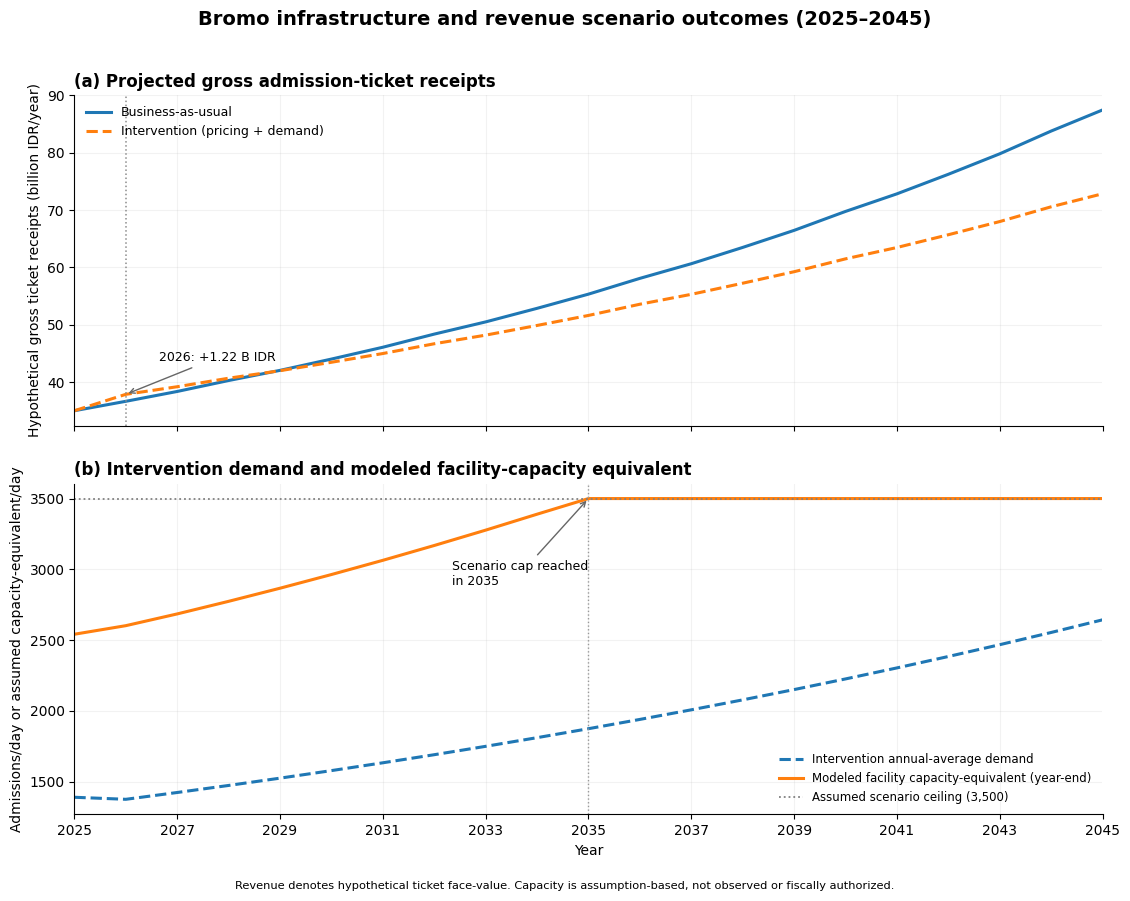

Saved: /mnt/data/ATR_Fig7_Revenue_Facilities_Executed_300dpi.png


In [4]:
# Matplotlib visualization: data-driven, no image generator, two publication-style panels.
fig, axes = plt.subplots(2,1,figsize=(11.4,9.1),sharex=True,
                         gridspec_kw={'height_ratios':[1,1]})
a,b=axes
x=results['year']

# Panel (a): face-value tickets, not PNBP.
a.plot(x,results['BAU_gross_ticket_IDR']/1e9, lw=2.2,
       label='Business-as-usual')
a.plot(x,results['INT_gross_ticket_IDR']/1e9, lw=2.2,ls='--',
       label='Intervention (pricing + demand)')
a.axvline(2026,ls=':',lw=1.1,color='0.55')
a.set_ylabel('Hypothetical gross ticket receipts (billion IDR/year)')
a.set_title('(a) Projected gross admission-ticket receipts',loc='left',fontweight='bold')
a.legend(frameon=False,loc='upper left',fontsize=9)
a.grid(alpha=.16)
a.spines[['top','right']].set_visible(False)
r2026=results.loc[results.year==2026].iloc[0]
a.annotate(f"2026: +{(r2026.INT_gross_ticket_IDR-r2026.BAU_gross_ticket_IDR)/1e9:.2f} B IDR",
           (2026,r2026.INT_gross_ticket_IDR/1e9),
           xytext=(24,24),textcoords='offset points',fontsize=9,
           arrowprops={'arrowstyle':'->','color':'0.4'})

# Panel (b): facility capacity is a scenario-derived equivalent with an assumed ceiling,
# NOT observed park infrastructure or the official operating quota.
b.plot(x,results['INT_admissions_day'],lw=2.2,ls='--',
       label='Intervention annual-average demand')
b.plot(x,results['INT_facility_capacity_equiv_end_year'],lw=2.2,
       label='Modeled facility capacity-equivalent (year-end)')
b.axhline(FACILITY_EQUIV_CEILING,ls=':',lw=1.3,color='0.5',
          label='Assumed scenario ceiling (3,500)')
b.axvline(2035,ls=':',lw=1.0,color='0.6')
b.annotate('Scenario cap reached\nin 2035',
           (2035,3500), xytext=(-98,-62),textcoords='offset points',fontsize=9,
           arrowprops={'arrowstyle':'->','color':'0.4'})
b.set_ylabel('Admissions/day or assumed capacity-equivalent/day')
b.set_xlabel('Year')
b.set_title('(b) Intervention demand and modeled facility-capacity equivalent',
            loc='left',fontweight='bold')
b.legend(frameon=False,loc='lower right',fontsize=8.5)
b.grid(alpha=.16)
b.spines[['top','right']].set_visible(False)
b.set_xlim(2025,2045)
b.set_xticks(range(2025,2046,2))

fig.suptitle('Bromo infrastructure and revenue scenario outcomes (2025–2045)',
             fontsize=14,fontweight='bold')
fig.text(0.5,0.014,
         'Revenue denotes hypothetical ticket face-value. Capacity is assumption-based, not observed or fiscally authorized.',
         ha='center',fontsize=8.2)
fig.tight_layout(rect=(0,0.032,1,0.965),h_pad=2.2)
file_png=OUT/'ATR_Fig7_Revenue_Facilities_Executed_300dpi.png'
fig.savefig(file_png,dpi=300,bbox_inches='tight')
plt.show()
print('Saved:',file_png)
